# 04 · Modelo de Regresión Logística: probabilidad de defunción por dengue

**Proyecto final · Análisis Estadístico Multivariado**

**Entrada:** `datos-procesados/dengue_limpio.csv` (generado en `02_limpieza.ipynb` y explorado en `03_EDA.ipynb`).

**Objetivo:** estimar la probabilidad de que un paciente con dengue confirmado fallezca,

$$p = P(\text{DEFUNCION} = 1 \mid X) = \frac{1}{1 + e^{-(\beta_0 + \beta_1 x_1 + \dots + \beta_k x_k)}}$$

e interpretar el efecto de cada variable mediante su *odds ratio* $e^{\beta_j}$.

**Decisiones que vienen del EDA**

| Hallazgo del EDA | Decisión en este notebook |
|---|---|
| Solo 0.70 % de fallecidos | *Undersampling* a 75 % sobrevivientes / 25 % fallecidos; partición estratificada; se evalúa con recall, precision, F1 y ROC-AUC además de accuracy |
| La edad no es lineal en el log-odds (forma de "U") | Se agrega el término `EDAD_ANOS_2` (edad²) y se revisa gráficamente |
| `HOSPITALIZADO` refleja la gravedad del paciente | Se compara el modelo final con y sin esta variable |
| Muchas variables con asociación débil | Selección de variables con *backward selection* (p-value, AIC y BIC) |

**Contenido**

1. Preparación de los datos (forma de la edad en el log-odds y *undersampling*)
2. División en entrenamiento y prueba
3. Modelo completo
4. Selección de variables (*backward selection*)
5. Modelo final: interpretación de coeficientes y *odds ratios*
6. Análisis de la variable `HOSPITALIZADO`
7. Separabilidad de las probabilidades estimadas
8. Métricas de desempeño
9. Importancia de variables con SHAP
10. Conclusiones

## 1. Preparación de los datos

In [1]:
# Librerías
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, roc_auc_score
import warnings
warnings.filterwarnings('ignore')

# Cargar datos
dengue = pd.read_csv('datos-procesados/dengue_limpio.csv')
print('Dimensiones:', dengue.shape)
print(f"Tasa de mortalidad: {dengue['DEFUNCION'].mean() * 100:.2f} %")

Dimensiones: (251900, 29)
Tasa de mortalidad: 0.70 %


En el EDA se observó que la mortalidad tiene forma de "U" con respecto a la edad. Para que el modelo pueda capturar esa curvatura se agrega la variable **edad al cuadrado**. Con los dos términos, el log-odds de la edad es una parábola: $\beta_1 \cdot edad + \beta_2 \cdot edad^2$.

In [2]:
# Término cuadrático de la edad
dengue['EDAD_ANOS_2'] = dengue['EDAD_ANOS'] ** 2

# Variables independientes (X) y dependiente (y)
X = dengue.drop(columns=['ID_REGISTRO', 'DEFUNCION'])
y = dengue['DEFUNCION']
print('Variables independientes:', X.shape[1])
print(list(X.columns))

Variables independientes: 28
['HOMBRE', 'EDAD_ANOS', 'COSTERA', 'INDIGENA', 'HEMORRAGICOS', 'DIABETES', 'HIPERTENSION', 'ENFERMEDAD_RENAL', 'INMUNOSUPR', 'CIRROSIS_HEPATICA', 'EMBARAZO', 'HOSPITALIZADO', 'DENV2', 'DENV3', 'DENV4', 'SIN_SEROTIPO', 'MES_ENE', 'MES_FEB', 'MES_MAR', 'MES_ABR', 'MES_MAY', 'MES_JUN', 'MES_JUL', 'MES_AGO', 'MES_SEP', 'MES_NOV', 'MES_DIC', 'EDAD_ANOS_2']


### 1.1 ¿Cómo se ve $\beta_1 \cdot edad + \beta_2 \cdot edad^2$ frente a la mortalidad?

La regresión logística **no** supone que la probabilidad de fallecer cambie en línea recta con la edad. Lo que supone es que una transformación de la probabilidad, el **log-odds**, sí lo hace. Para revisar ese supuesto hay que calcular el log-odds directamente de los datos, sin usar el modelo, y ver qué forma tiene.

**De probabilidad a log-odds, paso a paso.** Se agrupan los pacientes en intervalos de 5 años de edad. En cada intervalo:

1. **Probabilidad (mortalidad):** fallecidos entre pacientes, $p = d / n$.
2. **Odds:** fallecidos entre sobrevivientes, $\dfrac{p}{1-p} = \dfrac{d}{n-d}$. Se lee como "por cada sobreviviente hay tantos fallecidos".
3. **Log-odds:** el logaritmo natural de los odds, $\ln\left(\dfrac{d}{n-d}\right)$. Es la escala en la que trabaja la regresión logística: $\ln\left(\frac{p}{1-p}\right) = \beta_0 + \beta_1 x_1 + \dots$

**Ejemplo con los menores de 5 años:** hay 6,828 pacientes y 80 fallecidos.

- Mortalidad: $80 / 6{,}828 = 1.17\,\%$.
- Odds: $80 / 6{,}748 = 0.0119$, es decir, aproximadamente 1 fallecido por cada 84 sobrevivientes.
- Log-odds: $\ln(0.0119) = -4.43$.

Como referencia para leer la gráfica: un log-odds de **−4.6 equivale a 1 %** de mortalidad, **−2.2 a 10 %** y **0 a 50 %**. Mientras más alto (menos negativo), mayor es el riesgo.

A este valor calculado con los datos se le llama **log-odds empírico**. En la práctica se le suma 0.5 a fallecidos y sobrevivientes, $\ln\left(\frac{d + 0.5}{n - d + 0.5}\right)$, para que no se indetermine si un intervalo no tiene muertes ($\ln 0$). Con miles de pacientes por intervalo, el cambio es mínimo.

Sobre esos puntos se dibujan dos modelos ajustados **solo con la edad** y con **todos** los datos (antes del *undersampling* y de la partición):

- **Solo lineal:** $\beta_0 + \beta_1 \cdot edad$, una recta en la escala del log-odds.
- **Cuadrático:** $\beta_0 + \beta_1 \cdot edad + \beta_2 \cdot edad^2$, una parábola en la escala del log-odds.

Si la edad fuera lineal en el log-odds, los puntos caerían sobre la recta.

Lineal:     log-odds = -5.9339 + 0.02912·edad   (AIC = 20,427.7)
Cuadrático: log-odds = -4.9291 + (-0.03615)·edad + 0.000757·edad²   (AIC = 20,139.9)
Vértice de la parábola (edad de menor riesgo): 23.9 años


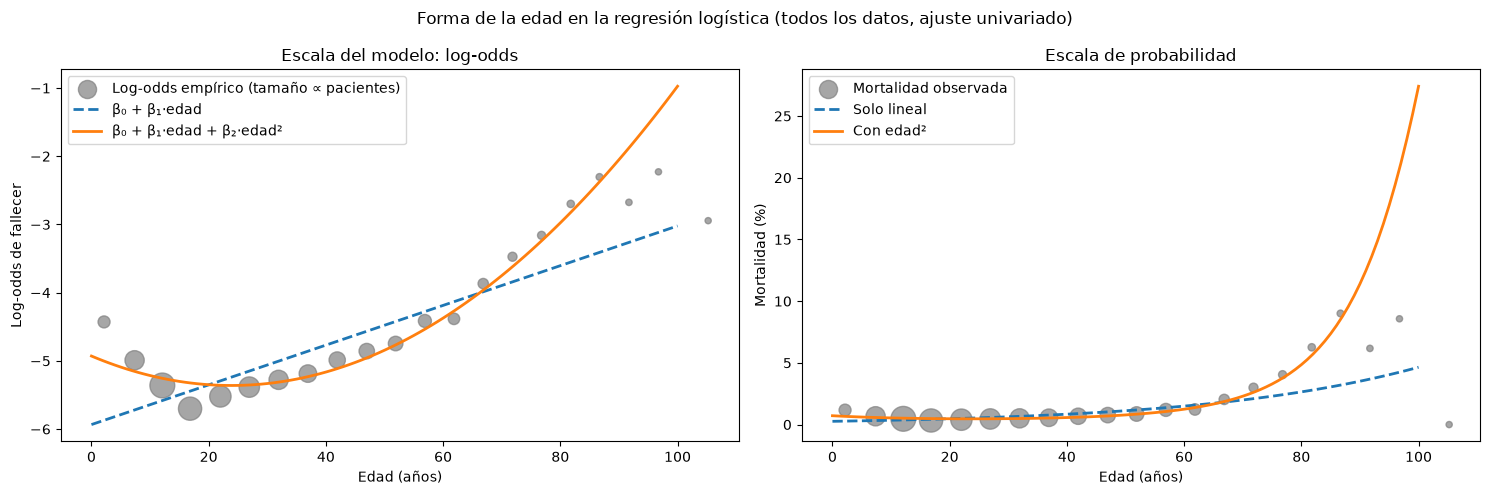

,Edad promedio,Pacientes (n),Fallecidos (d),Mortalidad (%),Odds (d / sobrevivientes),Log-odds empírico
EDAD_ANOS,,,,,,
0,2.1520,6828,80,1.1716,0.0119,-4.4288
5,7.3636,21399,144,0.6729,0.0068,-4.9911
10,12.0936,37311,174,0.4664,0.0047,-5.3605
15,16.8265,32252,107,0.3318,0.0033,-5.7005
20,21.9995,26974,107,0.3967,0.0040,-5.5212
25,26.9297,24421,111,0.4545,0.0046,-5.3846
30,31.9370,21373,108,0.5053,0.0051,-5.2781
35,36.9360,17353,96,0.5532,0.0056,-5.1865
40,41.9313,14681,99,0.6743,0.0068,-4.9874


In [3]:
# Log-odds empírico por intervalos de 5 años de edad
bins = np.arange(0, 105, 5)
grupo = pd.cut(dengue['EDAD_ANOS'], bins=np.append(bins, np.inf), right=False, labels=bins)
resumen_edad = dengue.groupby(grupo, observed=True)['DEFUNCION'].agg(n='size', d='sum')
resumen_edad['edad_media'] = dengue.groupby(grupo, observed=True)['EDAD_ANOS'].mean()
resumen_edad['logit_emp'] = np.log((resumen_edad['d'] + 0.5) / (resumen_edad['n'] - resumen_edad['d'] + 0.5))
resumen_edad['mortalidad'] = resumen_edad['d'] / resumen_edad['n']

# Ajustes univariados: solo edad y edad + edad²
logit_lineal = sm.Logit(dengue['DEFUNCION'], sm.add_constant(dengue[['EDAD_ANOS']])).fit(disp=0)
logit_cuad = sm.Logit(dengue['DEFUNCION'], sm.add_constant(dengue[['EDAD_ANOS', 'EDAD_ANOS_2']])).fit(disp=0)
b0, b1, b2 = logit_cuad.params
print(f'Lineal:     log-odds = {logit_lineal.params.iloc[0]:.4f} + {logit_lineal.params.iloc[1]:.5f}·edad   (AIC = {logit_lineal.aic:,.1f})')
print(f'Cuadrático: log-odds = {b0:.4f} + ({b1:.5f})·edad + {b2:.6f}·edad²   (AIC = {logit_cuad.aic:,.1f})')
print(f'Vértice de la parábola (edad de menor riesgo): {-b1 / (2 * b2):.1f} años')

edades_graf = np.arange(0, 101)
eta_lineal = logit_lineal.params.iloc[0] + logit_lineal.params.iloc[1] * edades_graf
eta_cuad = b0 + b1 * edades_graf + b2 * edades_graf ** 2
tamanos = 20 + 300 * resumen_edad['n'] / resumen_edad['n'].max()

fig, ejes = plt.subplots(1, 2, figsize=(15, 5))
ejes[0].scatter(resumen_edad['edad_media'], resumen_edad['logit_emp'], s=tamanos, color='gray', alpha=0.7,
                label='Log-odds empírico (tamaño ∝ pacientes)')
ejes[0].plot(edades_graf, eta_lineal, '--', lw=2, label='β₀ + β₁·edad')
ejes[0].plot(edades_graf, eta_cuad, lw=2, label='β₀ + β₁·edad + β₂·edad²')
ejes[0].set_xlabel('Edad (años)')
ejes[0].set_ylabel('Log-odds de fallecer')
ejes[0].set_title('Escala del modelo: log-odds')
ejes[0].legend()

ejes[1].scatter(resumen_edad['edad_media'], resumen_edad['mortalidad'] * 100, s=tamanos, color='gray', alpha=0.7,
                label='Mortalidad observada')
ejes[1].plot(edades_graf, 100 / (1 + np.exp(-eta_lineal)), '--', lw=2, label='Solo lineal')
ejes[1].plot(edades_graf, 100 / (1 + np.exp(-eta_cuad)), lw=2, label='Con edad²')
ejes[1].set_xlabel('Edad (años)')
ejes[1].set_ylabel('Mortalidad (%)')
ejes[1].set_title('Escala de probabilidad')
ejes[1].legend()
plt.suptitle('Forma de la edad en la regresión logística (todos los datos, ajuste univariado)')
plt.tight_layout()
plt.show()

pd.DataFrame({
    'Edad promedio': resumen_edad['edad_media'],
    'Pacientes (n)': resumen_edad['n'],
    'Fallecidos (d)': resumen_edad['d'],
    'Mortalidad (%)': resumen_edad['mortalidad'] * 100,
    'Odds (d / sobrevivientes)': resumen_edad['d'] / (resumen_edad['n'] - resumen_edad['d']),
    'Log-odds empírico': resumen_edad['logit_emp'],
}).round(4)

**Interpretación.**

- **La edad no es lineal en el log-odds.** En la gráfica izquierda, los puntos grises no siguen la recta punteada. Bajan de los 0 a los ~15–20 años (de −4.4 a −5.7) y después suben cada vez más rápido (−4.4 a los 60 años y −2.3 a los 85). La recta subestima el riesgo de los niños y de los adultos mayores y lo sobreestima entre los 20 y los 50 años.
- **La parábola se ajusta mucho mejor.** El coeficiente lineal es negativo ($\beta_1 = -0.036$) y el cuadrático positivo ($\beta_2 = 0.00076$), lo que forma una "U" con mínimo cerca de los **24 años**. El AIC baja ≈ 290 unidades respecto a la recta.
- **En la escala de probabilidad** (gráfica derecha), la mortalidad es casi plana (≈ 0.5 %) hasta los 60 años y después crece rápido: 2 % a los 65–69, 4 % a los 75–79 y 9 % a los 85–89.
- **El ajuste no es perfecto en los extremos.** En menores de 5 años la mortalidad observada (1.2 %) queda por encima de la parábola. Después de los 90 años la parábola sigue subiendo mientras los datos se estabilizan, pero con muy pocos pacientes (puntos pequeños), así que pesan poco en el ajuste.
- El modelo sigue siendo **lineal en los parámetros** ($\beta$); lo que cambia es que la edad entra con dos términos para representar la "U".

### 1.2 *Undersampling*: 75 % sobrevivientes / 25 % fallecidos

Solo el 0.70 % de los pacientes fallece. Para que el modelo vea más fallecidos en proporción, se hace un **submuestreo aleatorio de la clase mayoritaria**: se conservan **todos** los fallecidos y se toma al azar un número de sobrevivientes igual a 3 veces el número de fallecidos, de modo que la muestra queda con **75 % sobrevivientes y 25 % fallecidos**. Las secciones siguientes (partición, ajuste y evaluación) usan esta muestra.

In [4]:
fallecidos = dengue[dengue['DEFUNCION'] == 1]
sobrevivientes = dengue[dengue['DEFUNCION'] == 0].sample(n=3 * len(fallecidos), random_state=42)
dengue_us = pd.concat([fallecidos, sobrevivientes]).sample(frac=1, random_state=42)  # mezclar filas

pd.DataFrame({
    'Casos': [len(dengue), len(dengue_us)],
    'Fallecidos': [dengue['DEFUNCION'].sum(), dengue_us['DEFUNCION'].sum()],
    'Sobrevivientes': [(dengue['DEFUNCION'] == 0).sum(), (dengue_us['DEFUNCION'] == 0).sum()],
    'Mortalidad (%)': [dengue['DEFUNCION'].mean() * 100, dengue_us['DEFUNCION'].mean() * 100],
}, index=['Original', 'Undersampling 75/25']).round(2)

,Casos,Fallecidos,Sobrevivientes,Mortalidad (%)
Original,251900,1763,250137,0.7
Undersampling 75/25,7052,1763,5289,25.0


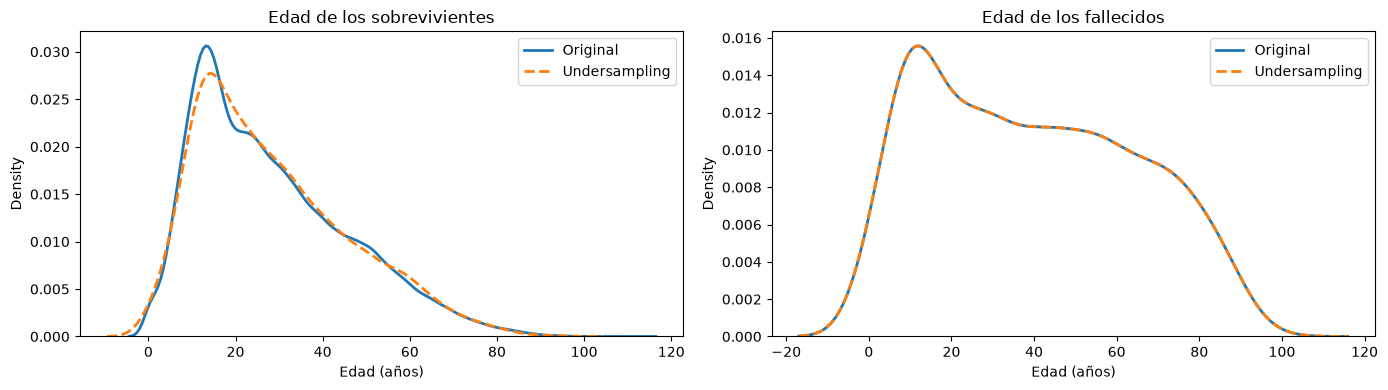

Dimensiones de X: (7052, 28)


In [5]:
# La edad conserva su distribución dentro de cada clase (el muestreo solo depende del desenlace)
fig, ejes = plt.subplots(1, 2, figsize=(14, 4))
for eje, clase, nombre in [(ejes[0], 0, 'Sobrevivientes'), (ejes[1], 1, 'Fallecidos')]:
    sns.kdeplot(dengue.loc[dengue['DEFUNCION'] == clase, 'EDAD_ANOS'], ax=eje, lw=2, label='Original')
    sns.kdeplot(dengue_us.loc[dengue_us['DEFUNCION'] == clase, 'EDAD_ANOS'], ax=eje, lw=2, ls='--', label='Undersampling')
    eje.set_title(f'Edad de los {nombre.lower()}')
    eje.set_xlabel('Edad (años)')
    eje.legend()
plt.tight_layout()
plt.show()

# Variables independientes (X) y dependiente (y) a partir de la muestra balanceada
X = dengue_us.drop(columns=['ID_REGISTRO', 'DEFUNCION'])
y = dengue_us['DEFUNCION']
print('Dimensiones de X:', X.shape)

**Interpretación.** La muestra balanceada tiene **7,052 pacientes**: los 1,763 fallecidos y 5,289 sobrevivientes. La distribución de la edad de los sobrevivientes muestreados es prácticamente igual a la original, así que el submuestreo aleatorio no introdujo un sesgo de edad dentro de cada clase.

## 2. División en entrenamiento y prueba

Si el modelo se evaluara con los mismos datos con los que se ajustó, las métricas serían optimistas: el modelo podría estar memorizando los datos (*overfitting*) en lugar de aprender patrones generales. Por eso se separa un **conjunto de prueba** que el modelo nunca ve durante el ajuste ni durante la selección de variables, y que solo se usa al final para medir su desempeño en datos nuevos.

- **70 % entrenamiento / 30 % prueba.**
- **Estratificado por `DEFUNCION`** (`stratify=y`): ambos conjuntos conservan la proporción 75 / 25 de la muestra balanceada.
- `random_state=42` para que el resultado sea reproducible.

In [6]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, stratify=y, random_state=42)

pd.DataFrame({
    'Casos': [len(y_train), len(y_test)],
    'Fallecidos': [y_train.sum(), y_test.sum()],
    'Mortalidad (%)': [y_train.mean() * 100, y_test.mean() * 100],
}, index=['Entrenamiento', 'Prueba']).round(3)

,Casos,Fallecidos,Mortalidad (%)
Entrenamiento,4936,1234,25.0
Prueba,2116,529,25.0


Ambos conjuntos conservan la misma tasa de mortalidad (25 %), así que la estratificación funcionó.

## 3. Modelo completo

Se ajusta primero una regresión logística con **todas** las variables, usando `statsmodels` sobre el conjunto de entrenamiento.

In [7]:
modelo_completo = sm.Logit(y_train, sm.add_constant(X_train)).fit(disp=0)
print(modelo_completo.summary())

                           Logit Regression Results                           
Dep. Variable:              DEFUNCION   No. Observations:                 4936
Model:                          Logit   Df Residuals:                     4907
Method:                           MLE   Df Model:                           28
Date:                Tue, 24 Nov 2026   Pseudo R-squ.:                  0.3264
Time:                        20:30:42   Log-Likelihood:                -1869.8
converged:                       True   LL-Null:                       -2775.7
Covariance Type:            nonrobust   LLR p-value:                     0.000
                        coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------
const                -4.2818      0.302    -14.163      0.000      -4.874      -3.689
HOMBRE                0.0566      0.083      0.683      0.495      -0.106       0.219
EDAD_ANOS            -0.

**Lectura de los estadísticos del modelo:**

- **Log-Likelihood (−1,869.8) vs. LL-Null (−2,775.7):** el modelo con predictores tiene una log-verosimilitud mucho mayor que el modelo sin predictores (que solo predice la tasa promedio de 25 %), es decir, las variables sí aportan información.
- **LLR p-value ≈ 0:** la prueba de razón de verosimilitudes rechaza que todos los coeficientes sean cero. El modelo en conjunto es significativo.
- **Pseudo R² = 0.326:** el modelo mejora en 32.6 % la log-verosimilitud del modelo nulo, un buen ajuste según el rango habitual (0.2 a 0.4).
- **Coeficientes:** son significativos (p-value < 0.05) la edad y edad², hemorrágicos, diabetes, enfermedad renal, hospitalización, DENV4 e indígena. No lo son sexo, entidad costera, hipertensión, inmunosupresión, cirrosis, embarazo, los demás serotipos y todos los meses. Esto justifica simplificar el modelo con *backward selection*.

## 4. Selección de variables: *backward selection*

Procedimiento:

1. Ajustar el modelo con todas las variables.
2. Identificar la variable con el **p-value más alto**.
3. Si ese p-value es mayor que el nivel de significancia ($\alpha = 0.05$), eliminar la variable y volver a ajustar el modelo.
4. Repetir hasta que todas las variables sean significativas.

En cada paso se registran el **AIC** y el **BIC** (criterios de información: penalizan la complejidad del modelo; **menor es mejor**). El BIC penaliza más el número de variables que el AIC.

In [8]:
alpha = 0.05
variables = list(X_train.columns)
pasos = []

while True:
    modelo = sm.Logit(y_train, sm.add_constant(X_train[variables])).fit(disp=0)
    p_values = modelo.pvalues.drop('const')
    peor = p_values.idxmax()
    pasos.append({'Núm. variables': len(variables), 'AIC': modelo.aic, 'BIC': modelo.bic,
                  'Variable con mayor p-value': peor, 'p-value': p_values.max()})
    if p_values.max() <= alpha:     # todas son significativas: se detiene
        break
    variables.remove(peor)          # se elimina la menos significativa

pasos = pd.DataFrame(pasos)
pasos['Acción'] = np.where(pasos['p-value'] > alpha, 'Se elimina', 'Se detiene (todas significativas)')
pasos.round(3)

,Núm. variables,AIC,BIC,Variable con mayor p-value,p-value,Acción
0,28,3797.650,3986.275,MES_ENE,0.941,Se elimina
1,27,3795.655,3977.776,MES_MAR,0.840,Se elimina
2,26,3793.696,3969.312,MES_DIC,0.831,Se elimina
3,25,3791.742,3960.854,MES_AGO,0.635,Se elimina
4,24,3789.968,3952.576,MES_SEP,0.713,Se elimina
5,23,3788.103,3944.207,COSTERA,0.582,Se elimina
6,22,3786.405,3936.004,CIRROSIS_HEPATICA,0.567,Se elimina
7,21,3784.735,3927.830,HOMBRE,0.499,Se elimina
8,20,3783.191,3919.782,MES_ABR,0.371,Se elimina
9,19,3781.981,3912.068,MES_FEB,0.342,Se elimina


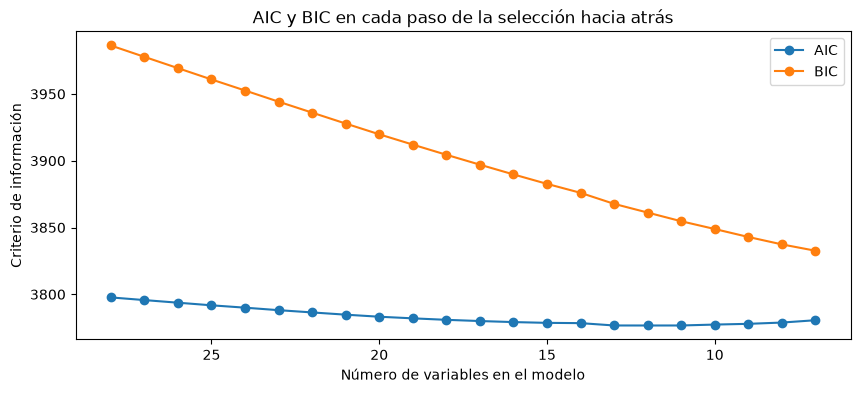

Variables finales: ['EDAD_ANOS', 'HEMORRAGICOS', 'DIABETES', 'ENFERMEDAD_RENAL', 'HOSPITALIZADO', 'DENV4', 'EDAD_ANOS_2']


In [9]:
plt.figure(figsize=(10, 4))
plt.plot(pasos['Núm. variables'], pasos['AIC'], marker='o', label='AIC')
plt.plot(pasos['Núm. variables'], pasos['BIC'], marker='o', label='BIC')
plt.gca().invert_xaxis()
plt.xlabel('Número de variables en el modelo')
plt.ylabel('Criterio de información')
plt.title('AIC y BIC en cada paso de la selección hacia atrás')
plt.legend()
plt.show()

print('Variables finales:', variables)

**Interpretación.**

- Se eliminaron **21 variables** en este orden: 5 dummies de mes (enero, marzo, diciembre, agosto, septiembre), entidad costera, cirrosis, sexo, 3 meses más (abril, febrero, noviembre), DENV2, embarazo, sin serotipo, DENV3, hipertensión, mayo, inmunosupresión, julio, junio e indígena. El modelo final tiene **7 variables**: edad, edad², hemorrágicos, diabetes, enfermedad renal, hospitalización y DENV4.
- El **BIC baja en todos los pasos** (de 3,986 a 3,833): según este criterio, el modelo de 7 variables es el mejor.
- El **AIC** baja poco y tiene su mínimo en 12 variables (3,776.6). El modelo final queda 3.9 unidades arriba, una diferencia pequeña pero mayor a 2. Es decir, el AIC preferiría conservar algunas variables más (inmunosupresión, julio, junio e indígena, todas con p-values entre 0.05 y 0.12), mientras que el BIC, que penaliza más la complejidad, prefiere el modelo más simple. Se elige el modelo de 7 variables porque todas son significativas y es el más sencillo de interpretar.
- **Nota sobre los meses:** como ningún mes quedó en el modelo, la estacionalidad no aporta información una vez que se consideran las demás variables.

In [10]:
# ¿Se justifica el término edad²? Modelo final con y sin él
sin_edad2 = [v for v in variables if v != 'EDAD_ANOS_2']
modelo_sin_edad2 = sm.Logit(y_train, sm.add_constant(X_train[sin_edad2])).fit(disp=0)

pd.DataFrame({
    'AIC': [modelo.aic, modelo_sin_edad2.aic],
    'BIC': [modelo.bic, modelo_sin_edad2.bic],
    'Pseudo R²': [modelo.prsquared, modelo_sin_edad2.prsquared],
}, index=['Con edad²', 'Sin edad²']).round(3)

,AIC,BIC,Pseudo R²
Con edad²,3780.571,3832.606,0.322
Sin edad²,3838.024,3883.554,0.311


**Interpretación.** Al quitar edad², el AIC sube 57 unidades y el BIC 51, y el pseudo R² baja de 0.322 a 0.311. El término cuadrático mejora claramente el modelo, lo que confirma lo observado en la gráfica de la sección 1.1: la relación entre la edad y el log-odds de fallecer **no es lineal**.

## 5. Modelo final: interpretación de coeficientes y *odds ratios*

In [11]:
modelo_final = sm.Logit(y_train, sm.add_constant(X_train[variables])).fit(disp=0)
print(modelo_final.summary())

                           Logit Regression Results                           
Dep. Variable:              DEFUNCION   No. Observations:                 4936
Model:                          Logit   Df Residuals:                     4928
Method:                           MLE   Df Model:                            7
Date:                Tue, 24 Nov 2026   Pseudo R-squ.:                  0.3219
Time:                        20:30:42   Log-Likelihood:                -1882.3
converged:                       True   LL-Null:                       -2775.7
Covariance Type:            nonrobust   LLR p-value:                     0.000
                       coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------
const               -3.8135      0.180    -21.191      0.000      -4.166      -3.461
EDAD_ANOS           -0.0308      0.007     -4.372      0.000      -0.045      -0.017
HEMORRAGICOS         1.1270 

In [12]:
# Odds ratio = e^beta, con su intervalo de confianza al 95 %
ic = np.exp(modelo_final.conf_int())
odds_ratios = pd.DataFrame({
    'Coeficiente (β)': modelo_final.params,
    'Odds ratio (e^β)': np.exp(modelo_final.params),
    'IC 95% inferior': ic[0],
    'IC 95% superior': ic[1],
    'p-value': modelo_final.pvalues,
}).drop(index='const').sort_values('Odds ratio (e^β)', ascending=False)
odds_ratios.round(4)

,Coeficiente (β),Odds ratio (e^β),IC 95% inferior,IC 95% superior,p-value
HOSPITALIZADO,3.5164,33.6625,25.2392,44.8969,0.0000
DENV4,1.6155,5.0305,1.6149,15.6702,0.0053
ENFERMEDAD_RENAL,1.2355,3.4402,1.7118,6.9135,0.0005
HEMORRAGICOS,1.1270,3.0863,1.7273,5.5146,0.0001
DIABETES,0.6772,1.9684,1.3920,2.7834,0.0001
EDAD_ANOS_2,0.0007,1.0007,1.0005,1.0008,0.0000
EDAD_ANOS,-0.0308,0.9696,0.9563,0.9831,0.0000


**Interpretación de los *odds ratios*** (manteniendo constantes las demás variables):

| Variable | OR (IC 95 %) | Interpretación |
|---|---|---|
| Hospitalizado | 33.7 (25.2–44.9) | Los odds de fallecer de un paciente hospitalizado son **34 veces** los de un paciente ambulatorio |
| DENV4 | 5.0 (1.6–15.7) | Multiplica los odds por 5, pero con un intervalo muy amplio (ver nota) |
| Enfermedad renal | 3.4 (1.7–6.9) | Tener enfermedad renal multiplica los odds de fallecer por 3.4 |
| Hemorrágicos | 3.1 (1.7–5.5) | Multiplica los odds por 3.1 |
| Diabetes | 2.0 (1.4–2.8) | Multiplica los odds por 2 |

Ningún intervalo de confianza incluye al 1, es decir, todas las variables **aumentan** el riesgo de forma significativa.

**Los *odds ratios* siguen siendo válidos con *undersampling*.** Como los sobrevivientes se eligieron al azar, sin ver sus características, el muestreo solo cambia el intercepto y los OR se interpretan de la forma usual.

**Nota sobre DENV4:** el resultado se basa en muy pocos pacientes: solo 31 en el conjunto de entrenamiento (11 fallecidos). En los datos completos, la mortalidad con DENV4 es de 0.86 % (12 de 1,396 pacientes), muy parecida a la general (0.70 %). Es probable que sea un efecto de la muestra y no un riesgo real, por lo que **no debe tomarse como una conclusión firme**.

**Edad:** sus coeficientes no se interpretan por separado. El coeficiente lineal es negativo (−0.031) y el cuadrático positivo (0.0007), lo que forma la parábola de la sección 1.1: el riesgo baja en las primeras edades y después sube cada vez más rápido. Su efecto se muestra en la siguiente gráfica. Como el modelo se ajustó con 25 % de fallecidos, primero se corrige el intercepto para que las probabilidades correspondan a la mortalidad real (0.70 %), con $\beta_0^{real} = \beta_0 - \ln\left(\frac{0.25 / 0.75}{\pi / (1 - \pi)}\right)$, donde $\pi$ es la tasa real de mortalidad.

Corrección del intercepto: β0 = -3.814 → -7.670

Ambulatorio: edad con menor riesgo = 23 años | prob. a los 0 años = 0.05 %, 20 años = 0.03 %, 60 años = 0.08 %, 85 años = 0.41 %
Hospitalizado: edad con menor riesgo = 23 años | prob. a los 0 años = 1.55 %, 20 años = 1.09 %, 60 años = 2.64 %, 85 años = 12.29 %


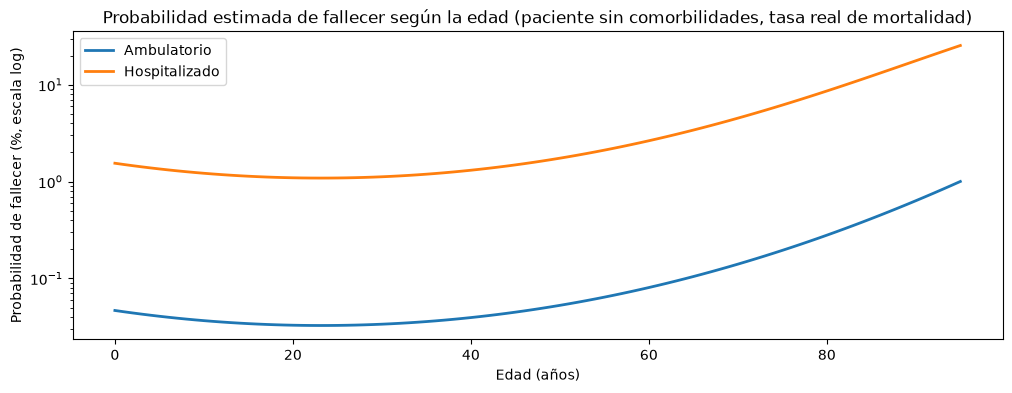

In [13]:
# Efecto de la edad: probabilidad estimada para un paciente de referencia
# (sin comorbilidades, sin hemorragia, serotipo distinto de DENV4), ambulatorio y hospitalizado.
# El modelo se ajustó con 25 % de fallecidos; se corrige el intercepto para regresar a la tasa real de mortalidad.
pi_real = dengue['DEFUNCION'].mean()
pi_muestra = y_train.mean()
correccion = np.log((pi_muestra / (1 - pi_muestra)) / (pi_real / (1 - pi_real)))
print(f'Corrección del intercepto: β0 = {modelo_final.params["const"]:.3f} → {modelo_final.params["const"] - correccion:.3f}\n')

edades = np.arange(0, 96)
plt.figure(figsize=(12, 4))
for hosp, etiqueta in [(0, 'Ambulatorio'), (1, 'Hospitalizado')]:
    perfil = pd.DataFrame(0, index=edades, columns=variables)
    perfil['EDAD_ANOS'] = edades
    perfil['EDAD_ANOS_2'] = edades ** 2
    perfil['HOSPITALIZADO'] = hosp
    log_odds = modelo_final.predict(sm.add_constant(perfil, has_constant='add'), which='linear') - correccion
    prob = 1 / (1 + np.exp(-log_odds.values))
    plt.plot(edades, prob * 100, lw=2, label=etiqueta)
    print(f'{etiqueta}: edad con menor riesgo = {edades[np.argmin(prob)]} años | '
          f'prob. a los 0 años = {prob[0]*100:.2f} %, 20 años = {prob[20]*100:.2f} %, '
          f'60 años = {prob[60]*100:.2f} %, 85 años = {prob[85]*100:.2f} %')
plt.yscale('log')
plt.xlabel('Edad (años)')
plt.ylabel('Probabilidad de fallecer (%, escala log)')
plt.title('Probabilidad estimada de fallecer según la edad (paciente sin comorbilidades, tasa real de mortalidad)')
plt.legend()
plt.show()

**Interpretación.** Al corregir el intercepto (de −3.81 a −7.67), las probabilidades regresan a la escala real. Para un paciente sin comorbilidades, el riesgo es mínimo alrededor de los **23 años** y aumenta en ambos extremos, como se vio en la sección 1.1. Para un paciente **hospitalizado**, la probabilidad de fallecer pasa de 1.1 % a los 20 años a 2.6 % a los 60 y a **12.3 % a los 85**; un recién nacido hospitalizado tiene 1.6 %. En pacientes **ambulatorios** el riesgo es mucho menor en todas las edades (0.03 % a los 20 años y 0.41 % a los 85).

Sin la corrección, el modelo daría probabilidades mucho más altas (por ejemplo, ≈ 87 % para un hospitalizado de 85 años), porque las calcula para una población donde 1 de cada 4 pacientes fallece.

## 6. Análisis de la variable `HOSPITALIZADO`

Uno de los supuestos de la regresión logística es que las variables independientes **no deben ser afectadas por la variable dependiente** (endogeneidad). La hospitalización no es causada por la muerte, pero sí es una **consecuencia de la gravedad** del paciente: los pacientes más graves se hospitalizan y también tienen mayor riesgo de morir. Por eso se compara el modelo final con el mismo modelo **sin** `HOSPITALIZADO`.

In [14]:
sin_hosp = [v for v in variables if v != 'HOSPITALIZADO']
modelo_sin_hosp = sm.Logit(y_train, sm.add_constant(X_train[sin_hosp])).fit(disp=0)

comparacion = pd.DataFrame({
    'AIC': [modelo_final.aic, modelo_sin_hosp.aic],
    'BIC': [modelo_final.bic, modelo_sin_hosp.bic],
    'Pseudo R²': [modelo_final.prsquared, modelo_sin_hosp.prsquared],
    'ROC-AUC (prueba)': [roc_auc_score(y_test, modelo_final.predict(sm.add_constant(X_test[variables]))),
                         roc_auc_score(y_test, modelo_sin_hosp.predict(sm.add_constant(X_test[sin_hosp])))],
}, index=['Con HOSPITALIZADO', 'Sin HOSPITALIZADO'])
print(comparacion.round(3))

# Odds ratios de las demás variables en ambos modelos
pd.DataFrame({
    'OR con HOSPITALIZADO': np.exp(modelo_final.params),
    'OR sin HOSPITALIZADO': np.exp(modelo_sin_hosp.params),
}).drop(index=['const', 'EDAD_ANOS', 'EDAD_ANOS_2']).round(2)

                        AIC       BIC  Pseudo R²  ROC-AUC (prueba)
Con HOSPITALIZADO  3780.571  3832.606      0.322             0.865
Sin HOSPITALIZADO  5037.682  5083.213      0.095             0.700


,OR con HOSPITALIZADO,OR sin HOSPITALIZADO
DENV4,5.03,1.65
DIABETES,1.97,2.64
ENFERMEDAD_RENAL,3.44,6.56
HEMORRAGICOS,3.09,3.76
HOSPITALIZADO,33.66,NaN


**Interpretación.**

- **Sin `HOSPITALIZADO` el modelo empeora mucho:** el AIC sube de 3,781 a 5,038, el pseudo R² baja de 0.322 a 0.095 y el ROC-AUC en prueba cae de 0.865 a 0.700. La hospitalización concentra la mayor parte de la capacidad predictiva.
- **Las comorbilidades aumentan su OR cuando se quita la hospitalización** (enfermedad renal pasa de 3.4 a 6.6, diabetes de 2.0 a 2.6 y hemorrágicos de 3.1 a 3.8). Esto indica que parte del efecto de las comorbilidades ocurre *a través* de la hospitalización: los pacientes con comorbilidades se agravan, se hospitalizan y por eso mueren más.
- **DENV4 hace lo contrario:** su OR baja de 5.0 a 1.7 sin la hospitalización. Su efecto aparece solo al comparar pacientes con la misma condición de hospitalización, lo que refuerza que es un resultado frágil.
- **Decisión:** se conserva `HOSPITALIZADO` porque mejora claramente el ajuste y la predicción, y porque la variable se conoce desde la primera atención del paciente (no depende del desenlace). Sin embargo, los coeficientes de las demás variables deben leerse como **efecto adicional a la hospitalización**, y el OR de 34 no significa que hospitalizar "cause" la muerte: refleja que se hospitaliza a los pacientes más graves.

## 7. Separabilidad de las probabilidades estimadas

Un modelo de regresión logística bien ajustado debería asignar probabilidades **bajas** a los sobrevivientes y **altas** a los fallecidos, de modo que las dos distribuciones queden separadas. Las probabilidades de esta sección son las del modelo **sin corregir** (escala de la muestra con 25 % de fallecidos). El eje horizontal se muestra en escala logarítmica y cada curva se normaliza por separado (`common_norm=False`) para poder compararlas a pesar del desbalance.

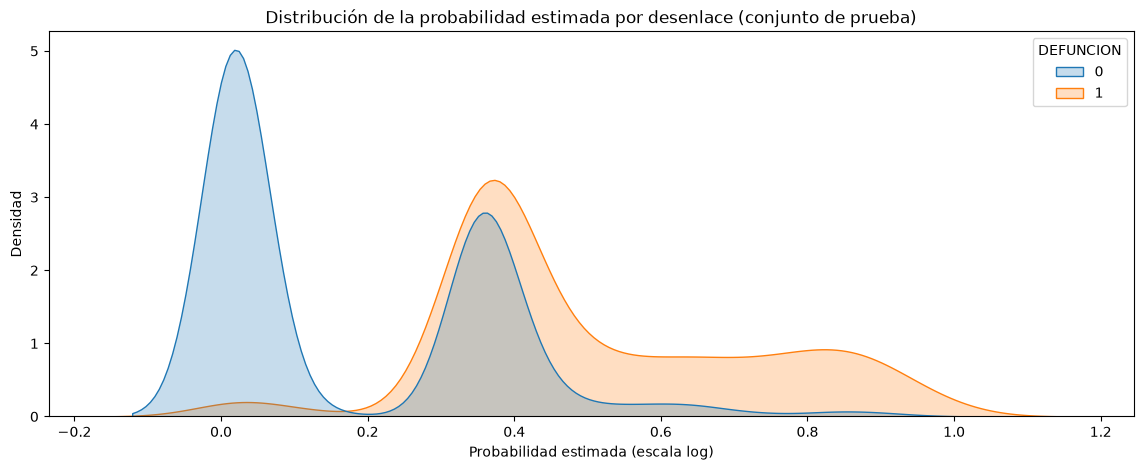

,mean,25%,50%,75%
Sobrevivió (0),0.1760,0.0161,0.0252,0.3538
Falleció (1),0.5081,0.3576,0.4052,0.6701


In [25]:
# Probabilidades estimadas en entrenamiento y prueba
prob_train = modelo_final.predict(sm.add_constant(X_train[variables]))
prob_test = modelo_final.predict(sm.add_constant(X_test[variables]))

def distribution_prob(y_real, probs, titulo):
    datos = pd.DataFrame({'DEFUNCION': y_real.values, 'predicted_probs': probs.values})
    plt.figure(figsize=(14, 5))
    sns.kdeplot(data=datos, x='predicted_probs', hue='DEFUNCION', fill=True, common_norm=False)
    plt.xlabel('Probabilidad estimada (escala log)')
    plt.ylabel('Densidad')
    plt.title(titulo)
    plt.show()

distribution_prob(y_test, prob_test, 'Distribución de la probabilidad estimada por desenlace (conjunto de prueba)')

pd.DataFrame({'Sobrevivió (0)': prob_test[y_test == 0].describe(),
              'Falleció (1)': prob_test[y_test == 1].describe()}).T[['mean', '25%', '50%', '75%']].round(4)

**Interpretación.**

- La distribución de los **sobrevivientes** tiene su pico principal alrededor de 2 % (mediana de 2.5 %), mientras que la de los **fallecidos** se concentra entre 30 % y 70 % (mediana de 40.5 %). La probabilidad promedio de los fallecidos (51 %) es casi 3 veces la de los sobrevivientes (18 %).
- Las distribuciones tienen **dos grupos**: el pico de la izquierda corresponde a pacientes **ambulatorios** y el de la derecha a **hospitalizados**. Casi todos los fallecidos están en el grupo de la derecha.
- La separación **no es perfecta**: los sobrevivientes que fueron hospitalizados (el segundo pico azul, alrededor de 35 %) se traslapan con los fallecidos. Dentro de los hospitalizados el modelo distingue menos, porque solo cuenta con la edad y las comorbilidades para diferenciarlos.
- Estas probabilidades están en la escala de la muestra balanceada. En la población real (0.70 % de mortalidad) serían mucho menores, pero el **orden** de los pacientes, y por lo tanto la separación entre grupos, es el mismo.

## 8. Métricas de desempeño

Definiciones (clase positiva = fallecido):

- **Accuracy**: proporción de predicciones correctas. Es engañosa con clases desbalanceadas.
- **Precision**: de los pacientes que el modelo marca como "fallece", qué proporción realmente falleció.
- **Recall (sensibilidad)**: de los pacientes que realmente fallecieron, qué proporción detectó el modelo.
- **F1-score**: media armónica de precision y recall.

En este problema, un **falso negativo** (no detectar a un paciente que va a morir) es mucho más costoso que un **falso positivo** (vigilar de más a un paciente que sobrevive), por lo que el **recall** de la clase 1 es la métrica más importante.

### 8.1 Umbral de 0.2

In [26]:
umbral = 0.2
for nombre, y_real, prob in [('ENTRENAMIENTO', y_train, prob_train), ('PRUEBA', y_test, prob_test)]:
    y_pred = (prob >= umbral).astype(int)
    print(f'===== {nombre} (umbral = {umbral}) =====')
    print('Matriz de confusión (filas: real 0/1, columnas: predicho 0/1)')
    print(confusion_matrix(y_real, y_pred))
    print(classification_report(y_real, y_pred, digits=3))

===== ENTRENAMIENTO (umbral = 0.2) =====
Matriz de confusión (filas: real 0/1, columnas: predicho 0/1)
[[2285 1417]
 [  51 1183]]
              precision    recall  f1-score   support

           0      0.978     0.617     0.757      3702
           1      0.455     0.959     0.617      1234

    accuracy                          0.703      4936
   macro avg      0.717     0.788     0.687      4936
weighted avg      0.847     0.703     0.722      4936

===== PRUEBA (umbral = 0.2) =====
Matriz de confusión (filas: real 0/1, columnas: predicho 0/1)
[[941 646]
 [ 19 510]]
              precision    recall  f1-score   support

           0      0.980     0.593     0.739      1587
           1      0.441     0.964     0.605       529

    accuracy                          0.686      2116
   macro avg      0.711     0.779     0.672      2116
weighted avg      0.845     0.686     0.706      2116



**Interpretación (umbral de 0.2).**

- Un paciente se marca como "fallece" si su probabilidad estimada es de 20 % o más.
- **Recall de 96.4 % en prueba:** el modelo detecta **510 de los 529 fallecidos** y deja pasar 19. En entrenamiento el recall es de 95.9 %.
- **Precision de 44.1 %:** de cada 100 pacientes marcados como "fallece", 44 fallecieron. El modelo marca a 1,156 de 2,116 pacientes de prueba (55 %).
- **F1 de 0.605** para la clase 1.
- **Accuracy de 68.6 %:** es menor que el 75 % que se obtendría prediciendo que nadie fallece, porque el umbral prioriza detectar fallecidos a costa de marcar a muchos sobrevivientes (646 falsos positivos).
- Las métricas de entrenamiento y prueba son parecidas, por lo que **no hay sobreajuste**.

### 8.2 Curva ROC y ROC-AUC

La **curva ROC** grafica, para todos los umbrales posibles, la tasa de verdaderos positivos (recall) contra la tasa de falsos positivos (1 − especificidad). El área bajo la curva (**ROC-AUC**) es la probabilidad de que, al tomar al azar un fallecido y un sobreviviente, el modelo le asigne mayor probabilidad al fallecido. Un valor de 0.5 equivale a adivinar al azar y 1 a una clasificación perfecta. Como regla general: 0.7–0.8 es aceptable, 0.8–0.9 es bueno y más de 0.9 es excelente.

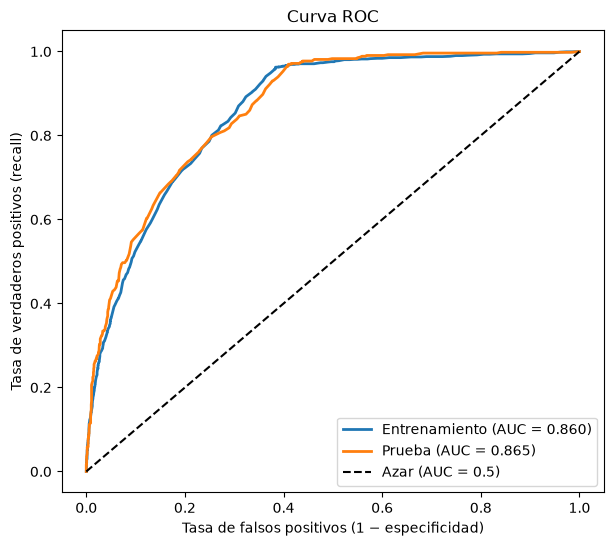

In [17]:
plt.figure(figsize=(7, 6))
for nombre, y_real, prob in [('Entrenamiento', y_train, prob_train), ('Prueba', y_test, prob_test)]:
    fpr, tpr, _ = roc_curve(y_real, prob)
    plt.plot(fpr, tpr, lw=2, label=f'{nombre} (AUC = {roc_auc_score(y_real, prob):.3f})')
plt.plot([0, 1], [0, 1], 'k--', label='Azar (AUC = 0.5)')
plt.xlabel('Tasa de falsos positivos (1 − especificidad)')
plt.ylabel('Tasa de verdaderos positivos (recall)')
plt.title('Curva ROC')
plt.legend()
plt.show()

**Interpretación.**

- El **ROC-AUC es de 0.860 en entrenamiento y 0.865 en prueba**: el modelo tiene una **buena capacidad de discriminación**. Si se elige al azar un paciente que falleció y uno que sobrevivió, en el 86.5 % de los casos el modelo asigna mayor probabilidad al que falleció.
- A diferencia de la accuracy y la precision, el AUC **no depende de la proporción de clases**.
- Las curvas de entrenamiento y prueba prácticamente se encimadan, lo que confirma que el modelo **generaliza bien** a datos nuevos.
- La curva sube rápido hasta un recall de ~0.96 con una tasa de falsos positivos cercana a 0.4; ese "codo" corresponde a separar pacientes hospitalizados de ambulatorios.

### 8.3 Umbral elegido con la curva ROC

Se elige el umbral que **maximiza la diferencia entre la tasa de verdaderos positivos y la de falsos positivos** (índice de Youden, $TPR - FPR$), que corresponde al punto de la curva ROC más alejado de la diagonal. El umbral se calcula **solo con entrenamiento** y después se aplica a prueba.

In [18]:
fpr, tpr, umbrales = roc_curve(y_train, prob_train)
umbral_roc = umbrales[np.argmax(tpr - fpr)]
print(f'Umbral elegido: {umbral_roc:.4f}  ({umbral_roc * 100:.2f} %)\n')

for nombre, y_real, prob in [('ENTRENAMIENTO', y_train, prob_train), ('PRUEBA', y_test, prob_test)]:
    y_pred = (prob >= umbral_roc).astype(int)
    print(f'===== {nombre} (umbral = {umbral_roc:.4f}) =====')
    print('Matriz de confusión (filas: real 0/1, columnas: predicho 0/1)')
    print(confusion_matrix(y_real, y_pred))
    print(classification_report(y_real, y_pred, digits=3))

Umbral elegido: 0.1434  (14.34 %)

===== ENTRENAMIENTO (umbral = 0.1434) =====
Matriz de confusión (filas: real 0/1, columnas: predicho 0/1)
[[2280 1422]
 [  46 1188]]
              precision    recall  f1-score   support

           0      0.980     0.616     0.756      3702
           1      0.455     0.963     0.618      1234

    accuracy                          0.703      4936
   macro avg      0.718     0.789     0.687      4936
weighted avg      0.849     0.703     0.722      4936

===== PRUEBA (umbral = 0.1434) =====
Matriz de confusión (filas: real 0/1, columnas: predicho 0/1)
[[938 649]
 [ 17 512]]
              precision    recall  f1-score   support

           0      0.982     0.591     0.738      1587
           1      0.441     0.968     0.606       529

    accuracy                          0.685      2116
   macro avg      0.712     0.779     0.672      2116
weighted avg      0.847     0.685     0.705      2116



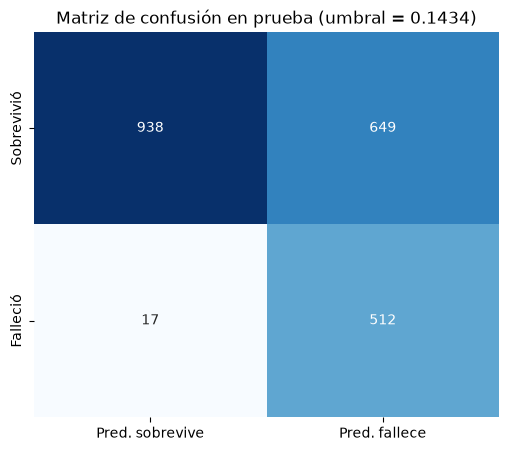

In [19]:
# Matriz de confusión del conjunto de prueba con el umbral elegido
matriz = confusion_matrix(y_test, (prob_test >= umbral_roc).astype(int))
plt.figure(figsize=(6, 5))
sns.heatmap(matriz, annot=True, fmt=',d', cmap='Blues', cbar=False,
            xticklabels=['Pred. sobrevive', 'Pred. fallece'], yticklabels=['Sobrevivió', 'Falleció'])
plt.title(f'Matriz de confusión en prueba (umbral = {umbral_roc:.4f})')
plt.show()

**Interpretación (umbral de 14.3 %).**

- El umbral elegido es **0.1434**: un paciente se marca como "alto riesgo" si su probabilidad estimada (en la escala de la muestra) es mayor a 14.3 %. Es bastante menor que 0.5 porque prioriza detectar fallecidos.
- **Recall de 96.8 % en prueba:** el modelo detecta **512 de los 529 fallecidos** y solo deja pasar 17. En entrenamiento el recall es de 96.3 %, así que el resultado es estable.
- **Precision de 44 %:** de cada 100 pacientes marcados como alto riesgo, 44 fallecen. El modelo marca a 1,161 de 2,116 pacientes de prueba (55 %). Esta precision está **inflada por la proporción de 25 % de fallecidos** en el conjunto de prueba.
- **F1 de 0.61 y accuracy de 68.5 %:** también dependen de la proporción de 25 % de fallecidos en el conjunto de prueba.

## 9. Importancia de variables con SHAP

**SHAP** (*SHapley Additive exPlanations*) es un método que explica **cuánto aporta cada variable a la predicción del modelo**.

La idea es sencilla: el modelo parte de una predicción promedio (la de un "paciente promedio") y cada variable **suma o resta** riesgo según el valor que tiene el paciente. Ese aporte es el **valor SHAP**:

- **SHAP positivo:** la variable **aumenta** el riesgo de fallecer de ese paciente.
- **SHAP negativo:** la variable **reduce** el riesgo.
- Entre más grande el valor (en absoluto), más pesa la variable.

En una regresión logística los valores SHAP están en la escala del **log-odds**, y se calculan como $\beta_j \times (x_j - \text{promedio de } x_j)$: el coeficiente de la variable por qué tan lejos está el paciente del promedio.

Como la edad entra al modelo con dos términos (`EDAD_ANOS` y `EDAD_ANOS_2`), sus valores SHAP se suman en una sola variable, `EDAD`.

Documentación: https://shap.readthedocs.io/en/latest/

In [20]:
import shap

# Explicador para modelos lineales: usa los coeficientes del modelo final y el conjunto de entrenamiento como referencia
coeficientes = modelo_final.params.drop('const').values
intercepto = modelo_final.params['const']
fondo = shap.maskers.Independent(X_train[variables], max_samples=len(X_train))
explainer = shap.LinearExplainer((coeficientes, intercepto), fondo)

# Valores SHAP de los pacientes de prueba
shap_values = pd.DataFrame(explainer.shap_values(X_test[variables]), columns=variables, index=X_test.index)

# Juntar los dos términos de la edad en una sola variable
shap_values['EDAD'] = shap_values['EDAD_ANOS'] + shap_values['EDAD_ANOS_2']
shap_values = shap_values.drop(columns=['EDAD_ANOS', 'EDAD_ANOS_2'])
datos = X_test[variables].drop(columns=['EDAD_ANOS_2']).rename(columns={'EDAD_ANOS': 'EDAD'})[shap_values.columns]

# Objeto que usan las gráficas de shap
explicacion = shap.Explanation(values=shap_values.values,
                               base_values=np.full(len(shap_values), explainer.expected_value),
                               data=datos.values,
                               feature_names=list(shap_values.columns))

### 9.1 Importancia de las variables dentro del modelo

Se calcula el **promedio del valor absoluto de SHAP** de cada variable sobre todos los pacientes de prueba. Indica cuánto mueve esa variable, en promedio, las predicciones del modelo.

HOSPITALIZADO       77.1
EDAD                15.3
DIABETES             3.5
HEMORRAGICOS         1.8
ENFERMEDAD_RENAL     1.5
DENV4                0.8
Name: % de la importancia total, dtype: float64


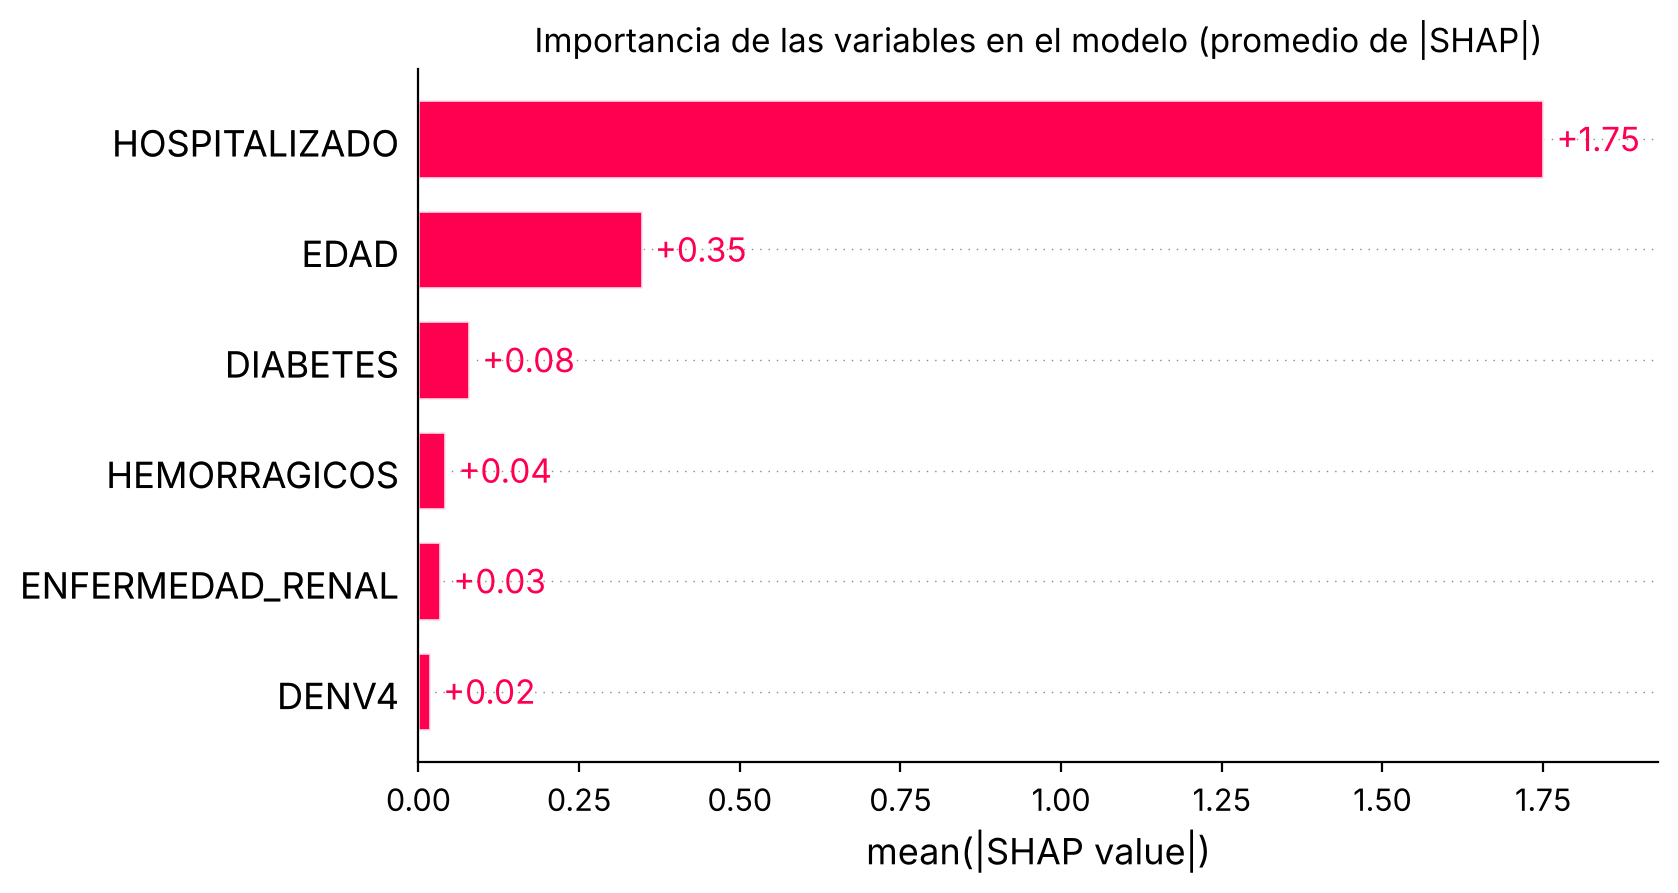

In [21]:
importancia = shap_values.abs().mean().sort_values(ascending=False)
print((importancia / importancia.sum() * 100).round(1).rename('% de la importancia total'))

shap.plots.bar(explicacion, show=False)
plt.title('Importancia de las variables en el modelo (promedio de |SHAP|)')
plt.show()

**Interpretación.**

- **`HOSPITALIZADO` es la variable más importante (77 % de la importancia total).** Es la que más cambia la predicción del modelo.
- **La edad es la segunda (15 %).** Entre hospitalización y edad suman el 92 % de la importancia.
- **Diabetes, hemorrágicos, enfermedad renal y DENV4 pesan poco en conjunto (8 %).** No es porque su efecto sea pequeño, sino porque **pocos pacientes las tienen**: el promedio incluye a todos los que no tienen la condición, para quienes la variable aporta casi cero.

### 9.2 Efecto de cada variable en los pacientes

En esta gráfica cada punto es un paciente de prueba:

- **Posición horizontal:** su valor SHAP (a la derecha aumenta el riesgo, a la izquierda lo reduce).
- **Color:** el valor de la variable (**rojo = alto**, **azul = bajo**; en las variables 0/1, rojo significa que el paciente tiene la condición).

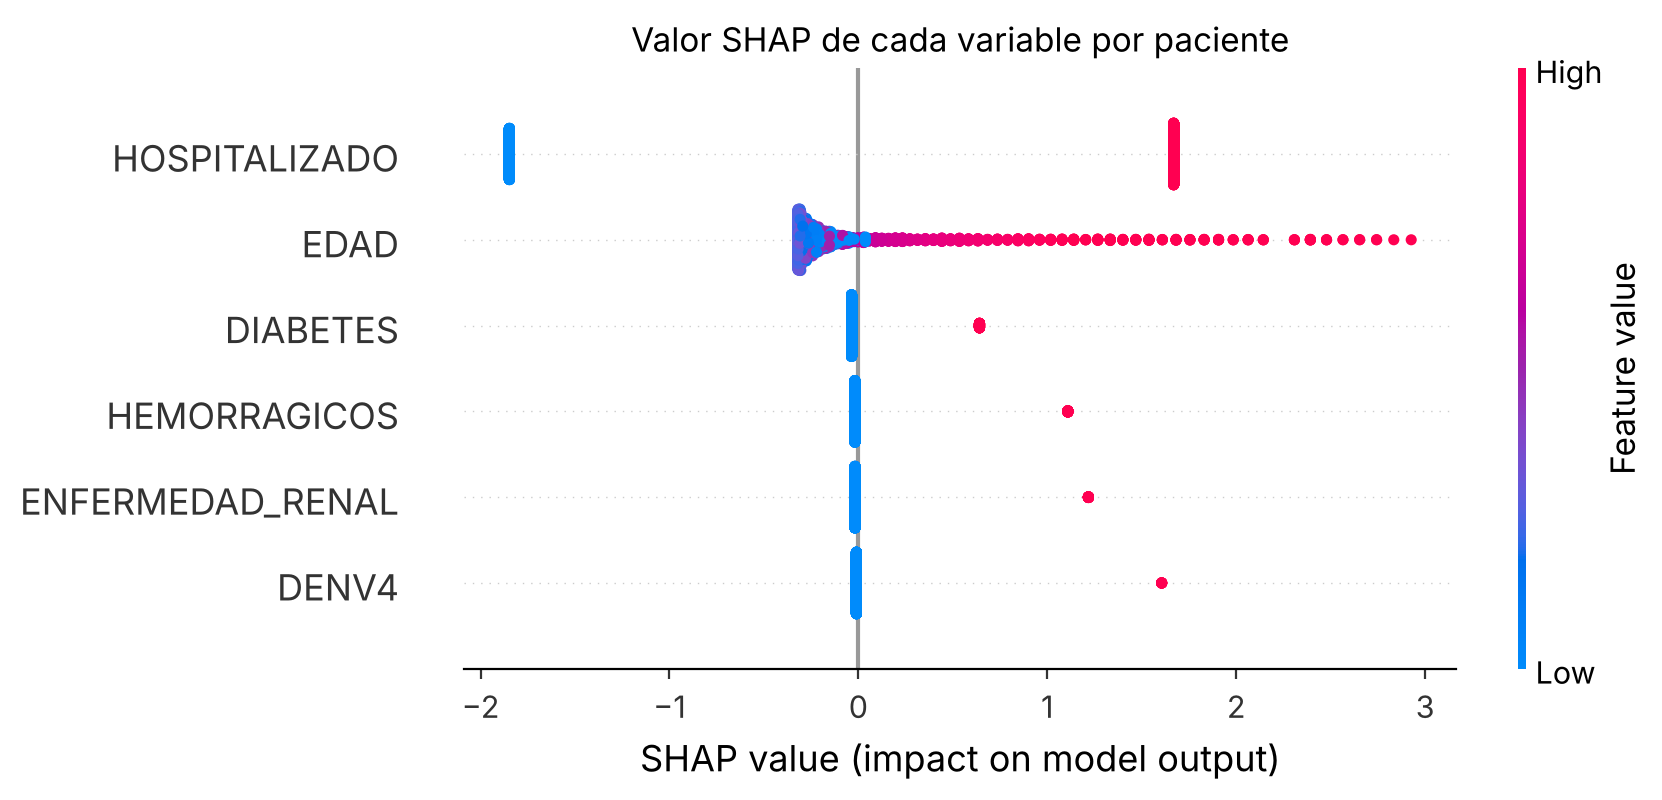

In [22]:
shap.plots.beeswarm(explicacion, show=False)
plt.title('Valor SHAP de cada variable por paciente')
plt.show()

**Interpretación.**

- **Hospitalización:** se ven dos grupos. Estar hospitalizado (rojo) **aumenta** el log-odds en +1.67, y ser ambulatorio (azul) lo **reduce** en −1.85.
- **Edad:** para los pacientes jóvenes (azul) el efecto es pequeño y negativo; para los adultos mayores (rojo) el riesgo sube mucho, hasta +2.9. En los pacientes de edad muy avanzada, la edad pesa más que la hospitalización.
- **Comorbilidades y DENV4:** la mayoría de los pacientes no las tiene y queda en cero (azul). Los pocos que sí las tienen (puntos rojos) reciben un aumento grande: enfermedad renal +1.22, hemorrágicos +1.11 y diabetes +0.64. Para ese paciente, la condición pesa casi tanto como la hospitalización.
- En todas las variables, el valor alto (rojo) está a la derecha: **todas aumentan el riesgo**, lo que coincide con que todos los *odds ratios* del modelo son mayores a 1.

### 9.3 Ejemplo: explicación de un paciente

La gráfica de cascada (*waterfall*) muestra cómo se construye la predicción de **un solo paciente**: empieza en la predicción promedio $E[f(X)]$ (abajo) y cada variable suma o resta su valor SHAP hasta llegar a la predicción final $f(x)$ (arriba). Se muestra el fallecido al que el modelo le asignó la mayor probabilidad.

Probabilidad estimada: 0.994


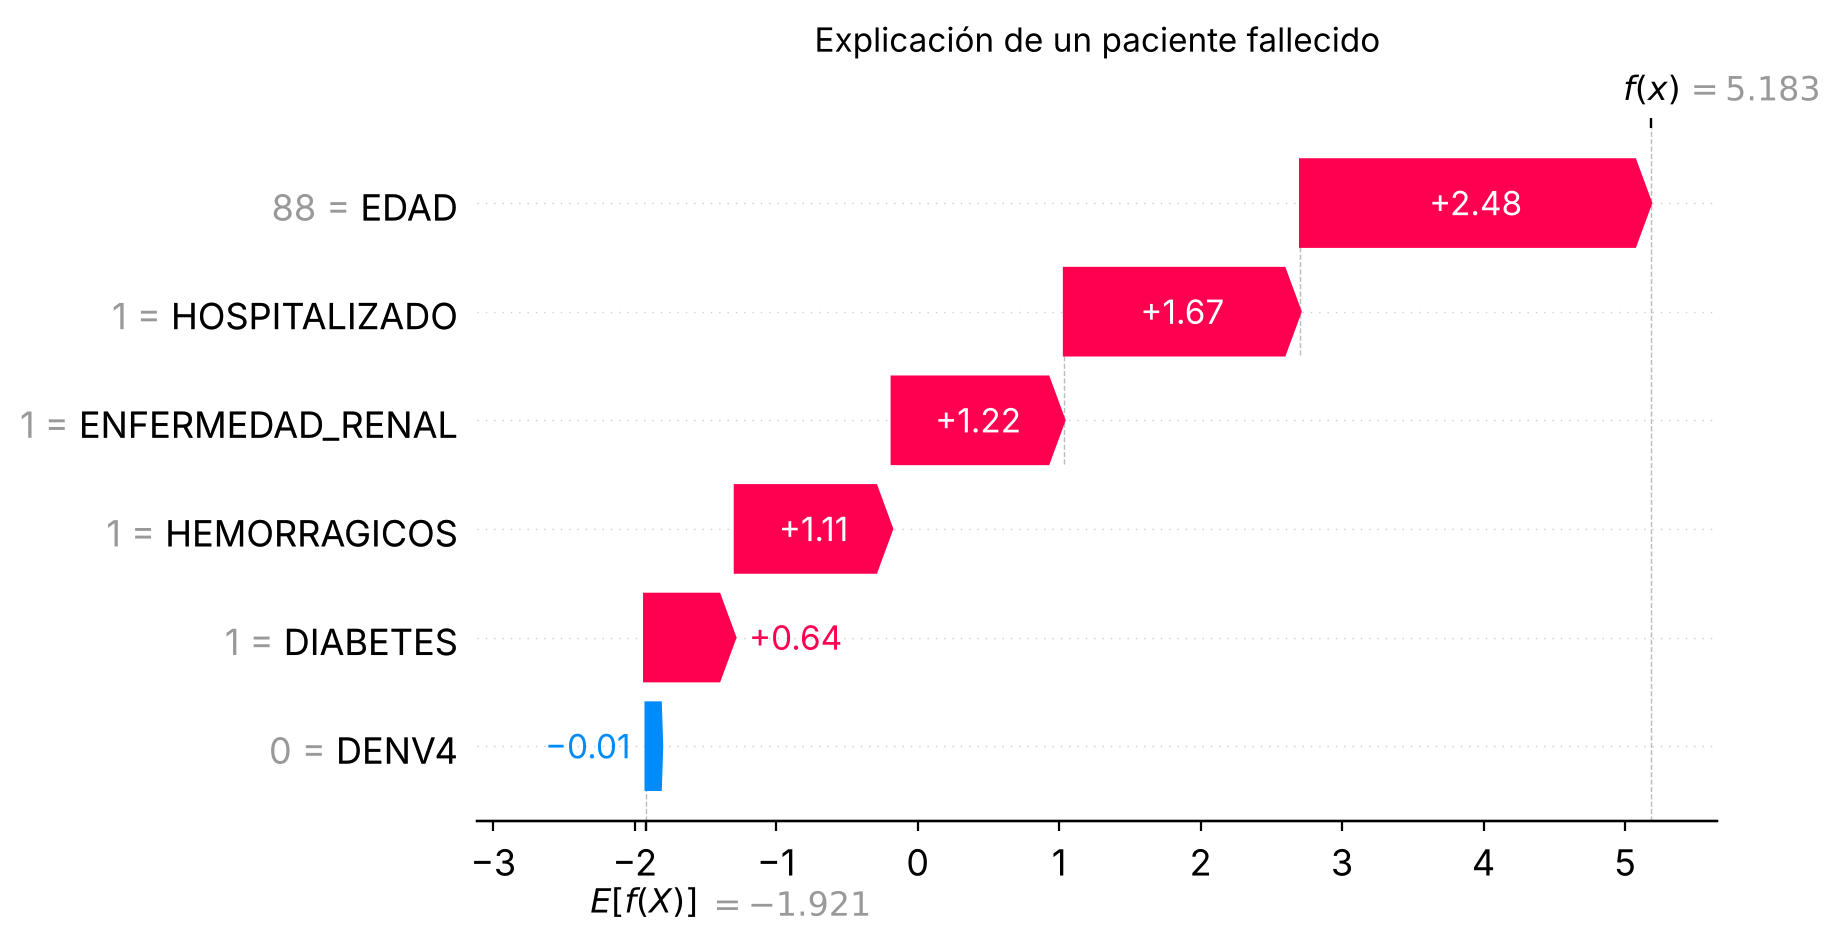

In [23]:
paciente = prob_test[y_test == 1].idxmax()
posicion = list(X_test.index).index(paciente)
print(f'Probabilidad estimada: {prob_test[paciente]:.3f}')

shap.plots.waterfall(explicacion[posicion], show=False)
plt.title('Explicación de un paciente fallecido')
plt.show()

**Interpretación.** El paciente tiene **88 años**, estuvo hospitalizado y tiene enfermedad renal, manifestaciones hemorrágicas y diabetes. Todas sus variables suman riesgo: la **edad** es la que más aporta (+2.48), seguida de la hospitalización (+1.67), la enfermedad renal (+1.22), los hemorrágicos (+1.11) y la diabetes (+0.64). Su log-odds pasa del promedio (−1.92) a +5.18, lo que da una probabilidad estimada de 99.4 % en la muestra balanceada.

### 9.4 Probabilidad de que la edad caiga en un punto crítico

Según el modelo y SHAP, las dos variables que más impactan son la **hospitalización** y la **edad**. Se usa la edad porque es la única variable continua. En el EDA (sección 7), ninguna distribución paramétrica pasó la prueba KS, y la **KDE** fue la que mejor describió la forma real de los datos, por lo que se usa su función de densidad.

**Punto crítico: 60 años.** Se elige por dos razones:

- **Evidencia del EDA:** a partir del grupo de 60–69 años la mortalidad (1.57 %) duplica el promedio general (0.70 %) y sigue subiendo: 3.39 % en 70–79 y 7.09 % en mayores de 80.
- **Criterio clínico y legal:** en México se considera persona adulta mayor a partir de los 60 años.

La pregunta es: **¿qué probabilidad hay de que un paciente con dengue tenga 60 años o más?** Con la KDE, esa probabilidad es el área bajo la curva a partir de los 60 años:

$$P(\text{edad} \geq 60) = \int_{60}^{\infty} \hat f_{KDE}(x)\,dx$$

que se calcula con `kde.integrate_box_1d(60, np.inf)`.

P(edad ≥ 60) según la KDE: 6.41 %
Proporción real de pacientes con 60 años o más: 6.64 %
Proporción de los fallecidos con 60 años o más: 25.01 %


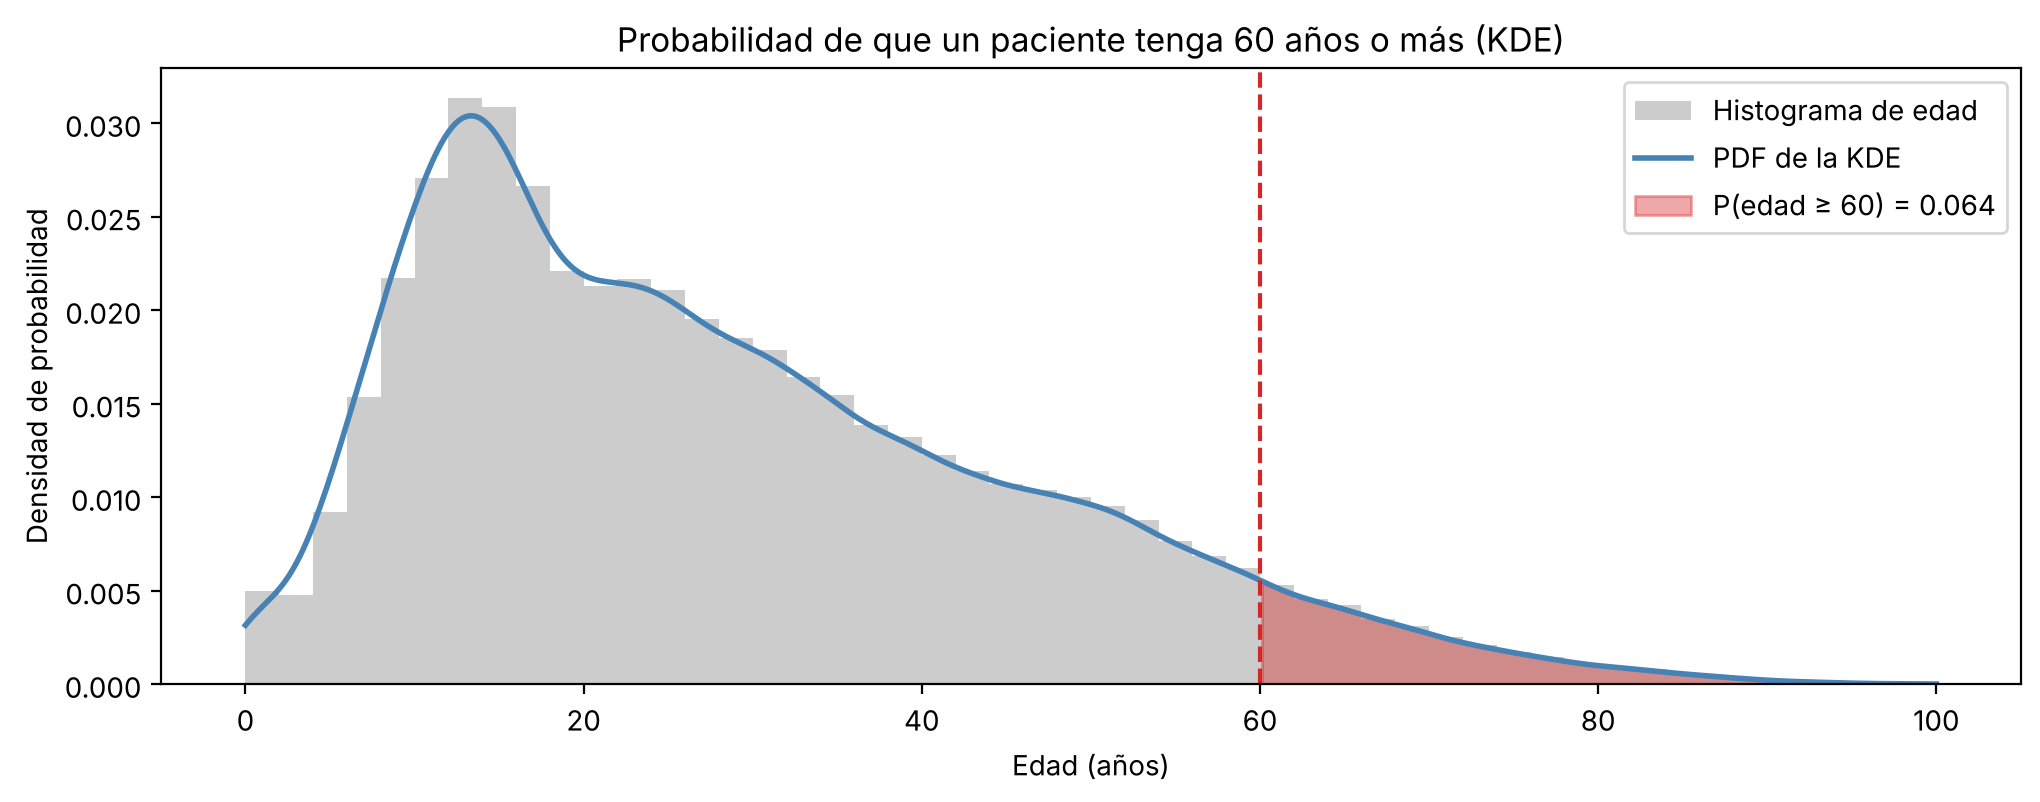

In [24]:
from scipy.stats import gaussian_kde

# KDE de la edad de todos los pacientes (kernel gaussiano, ancho de banda de Silverman, igual que en el EDA)
kde_edad = gaussian_kde(dengue['EDAD_ANOS'], bw_method='silverman')

punto_critico = 60
prob_kde = kde_edad.integrate_box_1d(punto_critico, np.inf)
print(f'P(edad ≥ {punto_critico}) según la KDE: {prob_kde * 100:.2f} %')

# Comparación con los datos reales
print(f"Proporción real de pacientes con {punto_critico} años o más: {(dengue['EDAD_ANOS'] >= punto_critico).mean() * 100:.2f} %")
print(f"Proporción de los fallecidos con {punto_critico} años o más: "
      f"{(dengue.loc[dengue['DEFUNCION'] == 1, 'EDAD_ANOS'] >= punto_critico).mean() * 100:.2f} %")

# Gráfica: histograma, PDF de la KDE y zona crítica sombreada
x = np.linspace(0, 100, 500)
pdf = kde_edad(x)
plt.figure(figsize=(12, 4))
plt.hist(dengue['EDAD_ANOS'], bins=np.arange(0, 102, 2), density=True, alpha=0.4, color='gray', label='Histograma de edad')
plt.plot(x, pdf, color='steelblue', lw=2, label='PDF de la KDE')
plt.fill_between(x, pdf, where=(x >= punto_critico), color='tab:red', alpha=0.4, label=f'P(edad ≥ {punto_critico}) = {prob_kde:.3f}')
plt.axvline(punto_critico, color='tab:red', linestyle='--')
plt.xlabel('Edad (años)')
plt.ylabel('Densidad de probabilidad')
plt.title('Probabilidad de que un paciente tenga 60 años o más (KDE)')
plt.legend()
plt.show()

**Interpretación.**

- Según la KDE, la probabilidad de que un paciente con dengue tenga **60 años o más es de 6.4 %**, muy cercana a la proporción real de los datos (6.6 %). Es decir, aproximadamente **1 de cada 16 pacientes** está en la zona crítica de edad.
- Sin embargo, en ese grupo ocurre el **25 % de las muertes** (1 de cada 4). Los pacientes de 60 años o más son pocos, pero concentran una parte muy grande de las defunciones.
- **Hospitalización:** al ser una variable binaria, su distribución es Bernoulli y la probabilidad de que un paciente sea hospitalizado es simplemente la proporción $\hat p$ = **38.9 %**. Este dato es directo y no requiere ajustar una distribución.
